# Alan 6 – AI Systems / Efficiency
# DistilBERT için Dynamic Quantization ve Batching: Doğruluk – Gecikme Ödünleşimi

**Problem.** Bir model offline testte yeterince doğru olabilir, ama serviste (production) her isteğe geç cevap veriyor ve çok kaynak tüketiyorsa kullanılamaz. Bu projede amaç, **doğruluğu ciddi düşürmeden** gecikmeyi (latency), model boyutunu ve kaynak kullanımını azaltmaktır.

| | |
|---|---|
| Model | `distilbert-base-uncased-finetuned-sst-2-english` (hazır, eğitilmiş) |
| Görev | Duygu analizi: cümle olumlu mu (1), olumsuz mu (0)? |
| Veri | SST-2 validation setinin **ilk 500** örneği (Hugging Face Datasets) |
| Donanım | **CPU** (GPU kullanılmıyor) |
| Optimizasyon 1 | Dynamic Quantization (FP32 → INT8, yalnızca Linear katmanlar) |
| Optimizasyon 2 | Batching (batch boyutu 1, 8, 16, 32) |

### Deney tasarımı: 2 × 4 faktöriyel

| | batch 1 | batch 8 | batch 16 | batch 32 |
|---|---|---|---|---|
| **FP32 (baseline)** | ✓ | ✓ | ✓ | ✓ |
| **INT8 (quantized)** | ✓ | ✓ | ✓ | ✓ |

- Aynı sütundaki iki hücrenin farkı → **yalnızca quantization etkisi**
- Aynı satırdaki hücrelerin farkı → **yalnızca batching etkisi**
- Her hücre: **10 warm-up + 100 ölçüm**, bu da **3 bağımsız tekrar** (run) halinde yapılır.

### Bu notebook nasıl çalıştırılır?
1. Anaconda Prompt'u açın, `jupyter notebook` yazın ve bu dosyayı açın.
2. Menüden **Kernel → Restart & Run All** seçin. İlk çalıştırmada model (~260 MB) ve veri indirilir.
3. Toplam süre sıradan bir dizüstü bilgisayarda yaklaşık 15–25 dakikadır. Çalışırken bilgisayarda ağır başka iş yapmayın; ölçümleri bozar.
4. Bütün çıktılar `results/` klasörüne yazılır.

### Önceki çalışmanın sonuçları (yalnızca referans)

Aşağıdaki değerler **daha önceki, kodu artık elimizde olmayan** bir notebook'tan alınmıştır. Bu notebook'ta yeniden ölçülmezler; yalnızca Bölüm 19b'de yeni sonuçlarla **referans olarak** yan yana konur. Yeni çalıştırmanın sonucu gibi sunulmazlar.

Bir uyarı: Eski "tekil" ölçümlerde throughput × ortalama gecikme ≈ 16 örnek çıkıyor. Bu, ölçümlerin **batch boyutu 16 ile yapılmış olabileceğine** işaret eder. Ancak eski benchmark kodu elimizde olmadığı için bu **doğrulanmamış bir çıkarımdır.**

In [1]:
# Önceki çalışmadan elle aktarılan değerler (yeniden ölçülmedi, sadece referans).
OLD_RESULTS = {
    "FP32 (önceki)": {"accuracy_pct": 91.2, "p50_ms": 238.547, "p95_ms": 252.402,
                      "mean_ms": 239.172, "std_ms": 10.587, "throughput_sps": 66.897,
                      "process_rss_mb": 814, "model_size_mb": 255.43},
    "INT8 (önceki)": {"accuracy_pct": 90.8, "p50_ms": 79.139, "p95_ms": 83.824,
                      "mean_ms": 79.620, "std_ms": 2.632, "throughput_sps": 200.954,
                      "process_rss_mb": None, "model_size_mb": 132.29},
}
# Önceki çalışmanın batch=8 özeti (3 tekrarlı). Hangi tabana göre hesaplandığı kayıtlı değil.
OLD_BATCH8_SUMMARY = {"p95_azalma_pct": 60.64, "throughput_artis_pct": 158.98,
                      "accuracy_fark_puan": -1.00, "model_boyutu_azalma_pct": 48.21}
print("Önceki sonuçlar referans olarak kaydedildi (bu çalıştırmada ölçülmedi).")

Önceki sonuçlar referans olarak kaydedildi (bu çalıştırmada ölçülmedi).


## 2. Kullanılacak kütüphaneler

**Ne yapıyoruz?** Önce eksik paket var mı diye bakıyoruz, sonra kütüphaneleri içe aktarıyoruz (`import`).

| Kütüphane | Ne için? |
|---|---|
| `torch` (PyTorch) | Modeli çalıştırmak ve quantization uygulamak |
| `transformers` | Hazır DistilBERT modelini ve tokenizer'ı indirmek |
| `datasets` | SST-2 veri setini indirmek |
| `numpy`, `pandas` | Hesaplama ve tablolar |
| `matplotlib` | Grafikler |
| `psutil` | Bellek (RAM) ve donanım bilgisi |

Anaconda'da `numpy`, `pandas`, `matplotlib`, `psutil` genellikle hazır gelir. Aşağıdaki hücre eksik olanları `pip` ile kurar.

In [2]:
import importlib.util, subprocess, sys

gerekli = ["torch", "transformers", "datasets", "numpy", "pandas", "matplotlib", "psutil"]
eksik = []
for paket in gerekli:
    if importlib.util.find_spec(paket) is None:   # paket kurulu değilse None döner
        eksik.append(paket)

if len(eksik) > 0:
    print("Kuruluyor:", eksik)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *eksik])
    print("Kurulum bitti. Lütfen Kernel → Restart yapıp notebook'u baştan çalıştırın.")
else:
    print("Tüm paketler kurulu.")

Tüm paketler kurulu.


In [3]:
import os, json, time, math, random, platform, copy, gc, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import torch
import transformers
import datasets
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from datasets import load_dataset

warnings.filterwarnings("ignore")   # sürüm uyarıları çıktıyı kalabalıklaştırmasın
print("İçe aktarma tamam.")

C:\Users\Merve Kartal\.conda\envs\ai-efficiency\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


İçe aktarma tamam.


### Deney ayarları

Bütün sabitler tek bir yerde. Bir şeyi değiştirmek isterseniz **yalnızca bu hücreyi** değiştirin; böylece hangi koşulda ölçüm yaptığınız her zaman bellidir.

- `N_WARMUP = 10`: ölçümden önce atılan ısınma turları
- `N_REPEAT = 100`: her ölçümde alınan tekrar sayısı
- `N_INDEPENDENT_RUNS = 3`: tüm 2×4 deneyin baştan kaç kez tekrarlandığı
- `PRACTICAL_TOLERANCE_PP = 1.0`: "pratikte önemsiz" saydığımız en büyük doğruluk kaybı (yüzde puan). Bu bir **proje varsayımıdır**; raporda gerekçesiyle belirtilmelidir.

`SMOKE_TEST` yalnızca internetsiz ortamda kodun hatasız çalıştığını denemek içindir. Siz ayarlamayın; normal çalıştırmada `False` olur.

In [4]:
SMOKE_TEST = os.environ.get("SMOKE_TEST") == "1"

MODEL_ID = "distilbert-base-uncased-finetuned-sst-2-english"
N_SAMPLES = 500                  # SST-2 validation setinin ilk 500 örneği
BATCH_SIZES = [1, 8, 16, 32]
N_WARMUP = 10
N_REPEAT = 100
N_INDEPENDENT_RUNS = 3
MAX_LEN = 128                    # bir cümle en fazla 128 token
SEED = 42                        # rastgelelik sabitlenir → aynı sonuçlar tekrar üretilebilir
PRACTICAL_TOLERANCE_PP = 1.0     # kabul edilebilir doğruluk kaybı (yüzde puan)
N_BOOTSTRAP = 10000

if SMOKE_TEST:                   # sadece kod testi için kısaltılmış ayarlar
    N_REPEAT, N_INDEPENDENT_RUNS, N_BOOTSTRAP = 30, 2, 2000

N_THREADS = torch.get_num_threads()   # PyTorch'un kullandığı CPU iş parçacığı sayısı
torch.set_num_threads(N_THREADS)      # tüm deney boyunca sabit kalsın

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

OUT = "results"
ART = "artifacts"
os.makedirs(OUT, exist_ok=True)
os.makedirs(ART, exist_ok=True)
print(f"Warm-up={N_WARMUP}, tekrar={N_REPEAT}, bağımsız run={N_INDEPENDENT_RUNS}, iş parçacığı={N_THREADS}")

Warm-up=10, tekrar=100, bağımsız run=3, iş parçacığı=8


## 3. Donanım ve yazılım ortamı

**Neden?** Gecikme ölçümü donanıma çok bağlıdır. Aynı model başka bir bilgisayarda iki kat hızlı çıkabilir. Bu yüzden:
1. Bütün karşılaştırmalar **aynı bilgisayarda, aynı oturumda** yapılmalı,
2. Hangi donanımda ölçtüğümüz kaydedilmeli (rapora yazılacak),
3. Kütüphane sürümleri kaydedilmeli (sonucu başkası tekrar üretebilsin diye).

Bu hücre ortamın bir "parmak izini" çıkarır ve `results/environment.json` dosyasına yazar. Notebook'un sonunda (Bölüm 20) tekrar kontrol edeceğiz.

**Bellek ölçüm yöntemi:** `psutil.Process().memory_info().rss`, sürecin o anda fiziksel RAM'de tuttuğu bellektir (RSS, *Resident Set Size*). Windows'ta bu değer işletim sisteminin **Working Set** değeridir; en yüksek değer `peak_wset` alanındadır. Linux'ta en yüksek değer `/proc/self/status` dosyasındaki `VmHWM` satırından okunur.

In [5]:
def get_cpu_name():
    # Windows'ta platform.processor() işlemci adını verir; Linux'ta /proc/cpuinfo dosyasına bakarız.
    name = platform.processor()
    if os.path.exists("/proc/cpuinfo"):
        with open("/proc/cpuinfo") as f:
            for line in f:
                if line.startswith("model name"):
                    name = line.split(":", 1)[1].strip()
                    break
    return name if name else "bilinmiyor"

def memory_method_name():
    if sys.platform == "win32":
        return "psutil memory_info().rss (Windows Working Set) + peak_wset"
    if sys.platform.startswith("linux"):
        return "psutil memory_info().rss + /proc/self/status VmHWM"
    return "psutil memory_info().rss + resource.ru_maxrss"

def environment_fingerprint():
    return {
        "isletim_sistemi": f"{platform.system()} {platform.release()}",
        "islemci": get_cpu_name(),
        "fiziksel_cekirdek": psutil.cpu_count(logical=False),
        "mantiksal_cekirdek": psutil.cpu_count(logical=True),
        "toplam_ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
        "torch_is_parcacigi": N_THREADS,
        "cihaz": "CPU",
        "gpu_var_ama_kullanilmiyor": torch.cuda.is_available(),
        "bellek_olcum_yontemi": memory_method_name(),
        "python": platform.python_version(),
        "torch": torch.__version__,
        "transformers": transformers.__version__,
        "datasets": datasets.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "psutil": psutil.__version__,
    }

ENV_START = environment_fingerprint()
with open(f"{OUT}/environment.json", "w", encoding="utf-8") as f:
    json.dump(ENV_START, f, indent=2, ensure_ascii=False)

for key, value in ENV_START.items():
    print(f"{key:28s}: {value}")

isletim_sistemi             : Windows 10
islemci                     : AMD64 Family 26 Model 96 Stepping 0, AuthenticAMD
fiziksel_cekirdek           : 8
mantiksal_cekirdek          : 16
toplam_ram_gb               : 16.3
torch_is_parcacigi          : 8
cihaz                       : CPU
gpu_var_ama_kullanilmiyor   : False
bellek_olcum_yontemi        : psutil memory_info().rss (Windows Working Set) + peak_wset
python                      : 3.11.18
torch                       : 2.15.0+cpu
transformers                : 5.22.1
datasets                    : 5.1.0
numpy                       : 2.4.6
pandas                      : 3.1.0
psutil                      : 7.2.2


**Çıktıyı nasıl okumalı?** `cihaz: CPU` yazmalı. `gpu_var_ama_kullanilmiyor: True` görürseniz sorun yok; bilgisayarınızda GPU var ama bilerek CPU'da ölçüyoruz, çünkü proje CPU inference üzerine. Bu tabloyu raporun "Deney Ortamı" bölümüne aynen koyabilirsiniz.

## 4. SST-2 veri setinin yüklenmesi

**SST-2 nedir?** Stanford Sentiment Treebank'in ikili (binary) sürümüdür. Film eleştirilerinden alınmış cümleler, insanlar tarafından olumlu (1) veya olumsuz (0) olarak etiketlenmiştir (Socher vd., 2013). GLUE kıyaslama setinin bir parçasıdır.

**Neden validation seti?** SST-2'nin test setindeki etiketler kamuya açık değildir. Validation seti etiketlidir ve modelimiz bu cümleleri eğitimde görmemiştir. Bu yüzden doğruluk ölçümü adildir.

**Neden ilk 500?** Proje kapsamında ölçüm süresini makul tutmak için. "İlk 500" seçimi rastgelelik içermez; herkes aynı 500 cümleyi alır. Sınırlılık: 500 örnekle ölçülen doğruluğun belirsizliği, 872 örneğin tamamına göre biraz daha yüksektir (Bölüm 15b'de güven aralığıyla göreceğiz).

In [6]:
def load_sst2_validation(n):
    if SMOKE_TEST:
        # İnternetsiz test için sentetik cümleler (gerçek sonuç vermez!)
        rng = random.Random(SEED)
        pos = ["great", "wonderful", "moving", "brilliant", "fun"]
        neg = ["boring", "awful", "dull", "weak", "messy"]
        filler = "the film story actor plot scene was and a very really it this of with".split()
        sentences, labs = [], []
        for i in range(n):
            y = rng.randint(0, 1)
            words = [rng.choice(filler) for _ in range(rng.randint(5, 35))]
            words.append(rng.choice(pos if y == 1 else neg))
            rng.shuffle(words)
            sentences.append(" ".join(words))
            labs.append(y)
        return sentences, np.array(labs)

    # Veri setinin Hugging Face'teki adı zamanla değişebildiği için sırayla deniyoruz.
    candidates = [("nyu-mll/glue", "sst2"), ("glue", "sst2"), ("stanfordnlp/sst2", None)]
    for name, config in candidates:
        try:
            if config is None:
                ds = load_dataset(name, split="validation")
            else:
                ds = load_dataset(name, config, split="validation")
            ds = ds.select(range(n))                    # ilk n örnek
            return list(ds["sentence"]), np.array(ds["label"])
        except Exception as e:
            print(f"{name} yüklenemedi ({type(e).__name__}), sıradaki deneniyor...")
    raise RuntimeError("SST-2 yüklenemedi. İnternet bağlantınızı kontrol edin.")

texts, labels = load_sst2_validation(N_SAMPLES)

print(f"Örnek sayısı: {len(texts)}")
print(f"Olumlu (1): {int(labels.sum())}  |  Olumsuz (0): {int((labels == 0).sum())}  |  Olumlu oranı: {labels.mean():.1%}")
print("\nİlk 3 örnek:")
for i in range(3):
    print(f"  [{labels[i]}] {texts[i]}")

Örnek sayısı: 500
Olumlu (1): 265  |  Olumsuz (0): 235  |  Olumlu oranı: 53.0%

İlk 3 örnek:
  [1] it 's a charming and often affecting journey . 
  [0] unflinchingly bleak and desperate 
  [1] allows us to hope that nolan is poised to embark a major career as a commercial yet inventive filmmaker . 


**Çıktıyı nasıl okumalı?** Sınıf dengesine bakın. Olumlu oranı %50'ye yakınsa doğruluk (accuracy) anlamlı bir metriktir. Örneğin veri %90 olumlu olsaydı, her şeye "olumlu" diyen aptal bir model bile %90 doğruluk alırdı. **Mülakat notu:** "Accuracy kullanmadan önce sınıf dengesini kontrol ettim" demek iyi bir alışkanlığı gösterir.

## 5. DistilBERT modelinin yüklenmesi

**DistilBERT nedir?** BERT'in "damıtılmış" (*distilled*) küçük kopyasıdır: 12 yerine 6 katman, yaklaşık 66 milyon parametre. Sanh vd. (2019) bu modelin BERT'in performansının büyük kısmını koruyup daha hızlı çalıştığını göstermiştir. Kullandığımız sürüm SST-2'nin eğitim setiyle zaten eğitilmiştir (*fine-tuned*). Bu yüzden biz **eğitim (training) yapmıyoruz**, yalnızca **çıkarım (inference)** yapıyoruz.

**Tokenizer nedir?** Model metin okuyamaz, sayı okur. Tokenizer cümleyi parçalara (token) böler ve her parçayı bir sayıya çevirir.

**Bu hücrede ayrıca:**
- Parametreleri türüne göre sayıyoruz: **embedding** (kelime gömme tabloları), **Linear** (tam bağlantılı katmanlar) ve diğerleri. Bu ayrım Bölüm 13'te "model neden %75 değil de ~%48 küçüldü?" sorusunu cevaplayacak.
- Model yüklenmeden önceki ve sonraki RSS değerini ölçüyoruz. Bu değer **ana Jupyter sürecine** aittir ve yaklaşıktır; daha temiz ölçüm Bölüm 14'tedir.

In [7]:
process = psutil.Process()                       # bu Python sürecinin kendisi
rss_before_load_mb = process.memory_info().rss / 1e6

if SMOKE_TEST:
    # İnternetsiz test: aynı mimaride ama rastgele ağırlıklı DistilBERT (doğruluk anlamsız olur)
    from transformers import BertTokenizerFast, DistilBertConfig, DistilBertForSequenceClassification
    vocab = ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"] + sorted({w for t in texts for w in t.split()})
    os.makedirs(f"{ART}/vocab", exist_ok=True)
    with open(f"{ART}/vocab/vocab.txt", "w") as f:
        f.write("\n".join(vocab))
    tokenizer = BertTokenizerFast(f"{ART}/vocab/vocab.txt")
    model_fp32 = DistilBertForSequenceClassification(DistilBertConfig(num_labels=2))
else:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    model_fp32 = AutoModelForSequenceClassification.from_pretrained(MODEL_ID)

model_fp32.eval()          # değerlendirme modu: dropout kapanır, sonuçlar deterministik olur
model_fp32.to("cpu")       # CPU inference

rss_after_load_mb = process.memory_info().rss / 1e6

# Modeli ve tokenizer'ı diske kaydediyoruz; Bölüm 14'teki ayrı süreç buradan okuyacak.
model_fp32.save_pretrained(f"{ART}/fp32")
tokenizer.save_pretrained(f"{ART}/fp32")

# Parametre sayımı
total_params = sum(p.numel() for p in model_fp32.parameters())
embedding_params = sum(p.numel() for name, p in model_fp32.named_parameters() if "embeddings" in name)
linear_params = 0
for module in model_fp32.modules():
    if isinstance(module, torch.nn.Linear):
        linear_params += module.weight.numel()
        if module.bias is not None:
            linear_params += module.bias.numel()
other_params = total_params - embedding_params - linear_params

print(f"Toplam parametre : {total_params/1e6:6.2f} M")
print(f"  Embedding      : {embedding_params/1e6:6.2f} M  ({embedding_params/total_params:.1%})")
print(f"  Linear         : {linear_params/1e6:6.2f} M  ({linear_params/total_params:.1%})")
print(f"  Diğer          : {other_params/1e6:6.2f} M  ({other_params/total_params:.1%})  (LayerNorm vb.)")
print(f"\nAna süreç RSS: yüklemeden önce {rss_before_load_mb:.0f} MB → sonra {rss_after_load_mb:.0f} MB "
      f"(fark ≈ {rss_after_load_mb - rss_before_load_mb:.0f} MB, yaklaşık)")
print("Etiketler:", model_fp32.config.id2label)

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  5.77it/s]

Toplam parametre :  66.96 M
  Embedding      :  23.84 M  (35.6%)
  Linear         :  43.10 M  (64.4%)
  Diğer          :   0.02 M  (0.0%)  (LayerNorm vb.)

Ana süreç RSS: yüklemeden önce 373 MB → sonra 770 MB (fark ≈ 397 MB, yaklaşık)
Etiketler: {0: 'NEGATIVE', 1: 'POSITIVE'}


**Çıktıyı nasıl okumalı?**
- Linear katmanlar parametrelerin yaklaşık **üçte ikisini**, embedding tablosu yaklaşık **üçte birini** oluşturur. Bunu aklınızda tutun.
- RSS farkı model ağırlıklarının boyutuna (~255 MB) yakın çıkmalıdır. Ama ana süreçte daha önce yüklenen kütüphaneler ve Python'un bellek yönetimi bu sayıyı etkiler; bu yüzden "yaklaşık" diyoruz.
- Etiketler `{0: 'NEGATIVE', 1: 'POSITIVE'}` olmalı; SST-2'deki 0/1 etiketleriyle aynı sırada.

## 6. Örnek tahminler

**Ne yapıyoruz?** Ölçümlere geçmeden önce modelin mantıklı çalıştığını gözle kontrol ediyoruz (*sanity check*).

**`predict_logits` fonksiyonu** projenin kalbidir; bütün doğruluk ve gecikme ölçümleri bu fonksiyonu kullanır. Böylece her ölçüm **aynı adımları** içerir:
1. Tokenization: cümleleri sayılara çevir, batch içindeki kısa cümleleri en uzun cümleye kadar doldur (*padding*),
2. Model çalıştır: `torch.inference_mode()` içinde, yani gradyan hesaplanmadan (eğitim yapmadığımız için gerekmez, daha hızlıdır).

Çıktı **logit**'tir: her sınıf için ham bir puan. `softmax` bu puanları olasılığa çevirir.

In [8]:
def predict_logits(model, batch_texts):
    # 1) Tokenization: metin → sayı. padding=True: batch'teki en uzun cümleye kadar doldur.
    encoded = tokenizer(batch_texts, padding=True, truncation=True, max_length=MAX_LEN,
                        return_token_type_ids=False, return_tensors="pt")
    # 2) Model çalıştırma (inference). inference_mode gradyan hesabını kapatır.
    with torch.inference_mode():
        output = model(**encoded)
    return output.logits

example_sentences = [
    "This movie was absolutely wonderful and moving.",
    "A boring, predictable and painfully long film.",
    "The acting was fine but the story went nowhere.",
    texts[0],
    texts[1],
]
logits = predict_logits(model_fp32, example_sentences)
probs = torch.softmax(logits, dim=1)

for sentence, p in zip(example_sentences, probs):
    label_id = int(p.argmax())
    label_name = model_fp32.config.id2label[label_id]
    print(f"{label_name:9s} (olasılık {float(p[label_id]):.3f})  ←  {sentence[:80]}")

POSITIVE  (olasılık 1.000)  ←  This movie was absolutely wonderful and moving.
NEGATIVE  (olasılık 1.000)  ←  A boring, predictable and painfully long film.
NEGATIVE  (olasılık 0.999)  ←  The acting was fine but the story went nowhere.
POSITIVE  (olasılık 1.000)  ←  it 's a charming and often affecting journey . 
NEGATIVE  (olasılık 0.999)  ←  unflinchingly bleak and desperate 


**Çıktıyı nasıl okumalı?** İlk cümle POSITIVE, ikinci cümle NEGATIVE çıkmalı. Üçüncü cümle karışık bir yorumdur; olasılığın 1'e daha uzak çıkması normaldir. Model emin değilse olasılık 0,5'e yaklaşır.

## 7. Baseline doğruluk ölçümü

**Baseline nedir?** Hiçbir optimizasyon uygulanmamış, orijinal modeldir. Bütün iyileştirmeleri buna göre ölçeriz. Baseline olmadan "hızlandı" demek anlamsızdır: neye göre?

**Ne yapıyoruz?** 500 cümlenin hepsini modele verip tahminleri gerçek etiketlerle karşılaştırıyoruz.

`Doğruluk (accuracy) = doğru tahmin sayısı / toplam örnek sayısı`

**Güven aralığı:** 500 örnekle ölçtüğümüz doğruluk, gerçek doğruluğun bir **tahminidir**. Wilson güven aralığı, gerçek doğruluğun %95 olasılıkla hangi aralıkta olduğunu gösterir. İstatistik derslerindeki oran (proportion) güven aralığının, uç değerlerde daha iyi çalışan bir sürümüdür.

**Karışıklık matrisi (confusion matrix):** Modelin hangi tür hatayı yaptığını gösterir: olumluya olumsuz mu diyor, olumsuza olumlu mu?

Ana doğruluk ölçümünü **batch=1** ile yapıyoruz. Nedeni: her cümle tek başına işlenir, başka cümlelerin dolgusundan etkilenmez. Diğer batch boyutlarındaki doğruluklar Bölüm 15b'de.

In [9]:
def evaluate_accuracy(model, batch_size):
    predictions = []
    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        logits = predict_logits(model, batch)
        predictions.extend(logits.argmax(dim=1).tolist())   # en yüksek puanlı sınıf = tahmin
    predictions = np.array(predictions)
    accuracy = float((predictions == labels).mean())
    return predictions, accuracy

def wilson_ci(successes, n, z=1.96):
    # Bir oranın (burada doğruluğun) %95 Wilson güven aralığı
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return center - half, center + half

preds_fp32_bs1, acc_fp32_bs1 = evaluate_accuracy(model_fp32, batch_size=1)
low, high = wilson_ci(int((preds_fp32_bs1 == labels).sum()), len(labels))

print(f"Baseline (FP32) doğruluk: {acc_fp32_bs1:.2%}   ({int((preds_fp32_bs1 == labels).sum())}/{len(labels)} doğru)")
print(f"%95 Wilson güven aralığı: [{low:.2%}, {high:.2%}]")

confusion = pd.crosstab(pd.Series(labels, name="Gerçek"), pd.Series(preds_fp32_bs1, name="Tahmin"))
print("\nKarışıklık matrisi (0=olumsuz, 1=olumlu):")
print(confusion)

Baseline (FP32) doğruluk: 91.20%   (456/500 doğru)
%95 Wilson güven aralığı: [88.39%, 93.38%]

Karışıklık matrisi (0=olumsuz, 1=olumlu):
Tahmin    0    1
Gerçek          
0       208   27
1        17  248


**Çıktıyı nasıl okumalı?**
- Bu modelin SST-2 validation setinin tamamında yayınlanan doğruluğu yaklaşık %91'dir. Sizin değeriniz buna yakınsa kurulum doğrudur.
- Güven aralığının genişliğine bakın; 500 örnekle yaklaşık ±2,5 puan olur. Bu, **iki model arasında 1 puanlık farkın tek başına çok şey söylemeyebileceği** anlamına gelir. Bunu Bölüm 15b'de doğru yöntemle test edeceğiz.
- Karışıklık matrisinde köşegen (sol üst, sağ alt) doğru tahminlerdir; diğer iki hücre hatalardır.

## 8. Baseline latency ve throughput benchmark (ön ölçüm)

**Latency (gecikme):** Modele bir girdi verildiği andan cevabın çıktığı ana kadar geçen süre (ms).

**Throughput (verim):** Saniyede işlenen örnek sayısı. `throughput = toplam örnek / toplam süre`.

**Benchmark kuralları (bu fonksiyon hepsini uygular):**
1. **Warm-up:** İlk çalıştırmalar yavaştır (bellek ayırma, önbellek dolması). 10 tur çalıştırıp atıyoruz.
2. **Sabit girdi:** Her tekrarda aynı cümleler kullanılır, böylece fark yalnızca sistemden gelir. Seed=42 ile 32 cümle bir kez seçilir. batch=8 bu listenin ilk 8 cümlesi, batch=16 ilk 16 cümlesidir.
3. **100 tekrar:** Her tekrar `time.perf_counter()` ile ayrı ayrı ölçülür. Tek ölçüm güvenilmezdir.
4. **Dağılım raporu:** p50 (medyan), p95, ortalama, standart sapma.

**Önemli tanım:** Burada ölçülen gecikme **bir batch'in tamamının** süresidir. batch=16'da 16 cümle birlikte işlenir ve her biri bu süre kadar bekler. Tokenization süresi de dahildir, çünkü gerçek bir serviste kullanıcı bu süreyi de bekler.

Bu bölüm bir **ön ölçümdür** (her hücre için 1 run). Nihai sonuçlar Bölüm 15'teki 3 bağımsız run'dan gelir.

In [10]:
BENCH_POOL = random.Random(SEED).sample(texts, max(BATCH_SIZES))   # seed=42 ile seçilen sabit 32 cümle
batch_inputs = {}
for bs in BATCH_SIZES:
    batch_inputs[bs] = BENCH_POOL[:bs]

def benchmark(model, batch_texts, n_warmup=N_WARMUP, n_repeat=N_REPEAT):
    # 1) Warm-up: ölçülmez, atılır
    for i in range(n_warmup):
        predict_logits(model, batch_texts)
    gc.collect()                      # ölçüm sırasında çöp toplayıcı devreye girmesin diye önceden temizle
    # 2) Ölçüm: her tekrar ayrı ayrı zamanlanır
    times_ms = []
    for i in range(n_repeat):
        start = time.perf_counter()
        predict_logits(model, batch_texts)
        end = time.perf_counter()
        times_ms.append((end - start) * 1000)
    return np.array(times_ms)

def summarize(times_ms, batch_size):
    total_seconds = times_ms.sum() / 1000
    return {
        "p50_ms": float(np.percentile(times_ms, 50)),
        "p95_ms": float(np.percentile(times_ms, 95)),
        "mean_ms": float(times_ms.mean()),
        "std_ms": float(times_ms.std(ddof=1)),        # örneklem standart sapması
        "throughput_sps": batch_size * len(times_ms) / total_seconds,
        "ms_per_sample": float(times_ms.mean() / batch_size),
    }

pre_rows = []
for bs in BATCH_SIZES:
    times = benchmark(model_fp32, batch_inputs[bs])
    s = summarize(times, bs)
    s["model"] = "FP32"
    s["batch_size"] = bs
    pre_rows.append(s)
    print(f"FP32 batch={bs:2d}: p50={s['p50_ms']:8.2f} ms  p95={s['p95_ms']:8.2f} ms  "
          f"std={s['std_ms']:6.2f} ms  throughput={s['throughput_sps']:7.1f} örnek/s")

FP32 batch= 1: p50=   18.01 ms  p95=   20.30 ms  std=  1.11 ms  throughput=   55.2 örnek/s
FP32 batch= 8: p50=  107.80 ms  p95=  116.16 ms  std=  4.37 ms  throughput=   73.6 örnek/s
FP32 batch=16: p50=  213.87 ms  p95=  286.14 ms  std= 30.06 ms  throughput=   70.5 örnek/s
FP32 batch=32: p50=  486.34 ms  p95=  517.85 ms  std= 17.43 ms  throughput=   65.2 örnek/s


**Çıktıyı nasıl okumalı?**
- **p50**: tipik çağrı süresi. **p95**: her 20 çağrıdan birinin en az bu kadar sürdüğü değer, yani "kötü durumlar".
- p95 ile p50 arasındaki fark ve standart sapma **varyansı** gösterir. Fark küçükse sistem kararlıdır.
- batch büyüdükçe **çağrı süresi artar**, ama **throughput** genellikle artar. Çünkü işlemci birçok cümleyi birlikte daha verimli işler.

## 9. Dynamic Quantization

**Quantization (nicemleme) nedir?** Model ağırlıkları normalde 32 bitlik ondalıklı sayılardır (**FP32**, 4 bayt). Quantization bunları 8 bitlik tam sayılara (**INT8**, 1 bayt) çevirir. Her ağırlık 256 olası değerden birine yuvarlanır ve bir **ölçek (scale)** katsayısıyla geri çevrilebilir:

`gerçek değer ≈ ölçek × (int8 değer − sıfır noktası)`

Bir benzetme: 16 milyon renkli bir fotoğrafı 256 renge indirmek. Dosya küçülür, göz çoğu zaman farkı anlamaz.

**Dynamic (dinamik) ne demek?**
- **Ağırlıklar** önceden, bir kez INT8'e çevrilir.
- **Aktivasyonlar** (katmanlar arasında akan ara değerler) her çağrıda, o anki verinin minimum ve maksimumuna bakılarak **anında** ölçeklenir. Bu yüzden kalibrasyon verisi gerekmez; tek satırla uygulanır.

**Hangi katmanlar?** `{torch.nn.Linear}`: yalnızca tam bağlantılı katmanlar. Transformer'larda hesabın büyük kısmı bu katmanlardaki matris çarpımlarıdır. Embedding tablosu ve LayerNorm FP32 kalır.

**Neden hızlanır?** INT8 matris çarpımı CPU'da daha hızlıdır (özel komutlar) ve belleğe 4 kat daha az veri taşınır.

**Neden doğruluk değişebilir?** Yuvarlama küçük bir hata getirir. Karar sınırına çok yakın cümlelerde bu hata tahmini değiştirebilir.

In [11]:
try:
    from torch.ao.quantization import quantize_dynamic
except ImportError:                      # eski PyTorch sürümleri
    from torch.quantization import quantize_dynamic

# Quantized işlemleri yürüten motoru seç. Windows/Intel/AMD'de 'x86' veya 'fbgemm' kullanılır.
for engine in ["x86", "fbgemm", "qnnpack"]:
    if engine in torch.backends.quantized.supported_engines:
        torch.backends.quantized.engine = engine
        break
print("Quantization motoru:", torch.backends.quantized.engine)

# copy.deepcopy: orijinal modeli bozmamak için bir kopyasını quantize ediyoruz
model_int8 = quantize_dynamic(copy.deepcopy(model_fp32), {torch.nn.Linear}, dtype=torch.qint8)
model_int8.eval()

# Önce / sonra: ilk transformer katmanındaki bir Linear katman
print("\nÖnce (FP32):", model_fp32.distilbert.transformer.layer[0].attention.q_lin)
print("Sonra (INT8):", model_int8.distilbert.transformer.layer[0].attention.q_lin)

try:
    from torch.ao.nn.quantized.dynamic import Linear as QuantizedLinear
except ImportError:
    from torch.nn.quantized.dynamic import Linear as QuantizedLinear

n_linear_fp32 = 0
for module in model_fp32.modules():
    if isinstance(module, torch.nn.Linear):
        n_linear_fp32 += 1
n_quantized = 0
for module in model_int8.modules():
    if isinstance(module, QuantizedLinear):
        n_quantized += 1
print(f"\nFP32 modeldeki Linear katman sayısı : {n_linear_fp32}")
print(f"INT8'e çevrilen katman sayısı       : {n_quantized}")

Quantization motoru: onednn

Önce (FP32): Linear(in_features=768, out_features=768, bias=True)
Sonra (INT8): DynamicQuantizedLinear(in_features=768, out_features=768, dtype=torch.qint8, qscheme=torch.per_tensor_affine)

FP32 modeldeki Linear katman sayısı : 38
INT8'e çevrilen katman sayısı       : 38


**Çıktıyı nasıl okumalı?** "Önce" satırında `Linear(in_features=768, out_features=768)`, "Sonra" satırında `DynamicQuantizedLinear(..., dtype=torch.qint8)` görmelisiniz. İki sayı eşit olmalı. DistilBERT'te her katmanda 6 Linear katman (q, k, v, out ve iki FFN katmanı) × 6 katman = 36, artı sınıflandırma başındaki 2 katman: toplam **38**.

## 10. Quantized model doğruluk ölçümü

Bölüm 7'deki fonksiyonun aynısını kullanıyoruz; tek fark model.

Burada ayrıca **tahmin uyumunu** (*agreement*) ölçüyoruz: iki modelin aynı tahmini verdiği cümle oranı. **Neden önemli?** İki model aynı doğruluğa sahip olup **farklı cümlelerde** hata yapabilir. Örneğin quantized model 3 cümleyi yeni yanlış yapıp 3 başka cümleyi düzeltirse doğruluk değişmez ama davranış değişmiştir.

**2×2 çapraz tablo** bu bilgiyi gösterir ve Bölüm 15b'deki McNemar testinin girdisidir.

In [12]:
preds_int8_bs1, acc_int8_bs1 = evaluate_accuracy(model_int8, batch_size=1)
low_q, high_q = wilson_ci(int((preds_int8_bs1 == labels).sum()), len(labels))

correct_fp32 = (preds_fp32_bs1 == labels)     # her cümle için True/False
correct_int8 = (preds_int8_bs1 == labels)
agreement = float((preds_fp32_bs1 == preds_int8_bs1).mean())

print(f"FP32 doğruluk: {acc_fp32_bs1:.2%}")
print(f"INT8 doğruluk: {acc_int8_bs1:.2%}   %95 Wilson GA: [{low_q:.2%}, {high_q:.2%}]")
print(f"Fark: {100*(acc_int8_bs1 - acc_fp32_bs1):+.2f} yüzde puan")
print(f"Tahmin uyumu: {agreement:.2%}  ({int((preds_fp32_bs1 != preds_int8_bs1).sum())} cümlede tahmin değişti)")

paired_table = pd.crosstab(pd.Series(np.where(correct_fp32, "FP32 doğru", "FP32 yanlış"), name=""),
                           pd.Series(np.where(correct_int8, "INT8 doğru", "INT8 yanlış"), name=""))
print("\n2×2 çapraz tablo (aynı 500 cümle):")
print(paired_table)

FP32 doğruluk: 91.20%
INT8 doğruluk: 90.40%   %95 Wilson GA: [87.50%, 92.68%]
Fark: -0.80 yüzde puan
Tahmin uyumu: 96.80%  (16 cümlede tahmin değişti)

2×2 çapraz tablo (aynı 500 cümle):
             INT8 doğru  INT8 yanlış
                                    
FP32 doğru          446           10
FP32 yanlış           6           38


**Çıktıyı nasıl okumalı?**
- Çapraz tablonun köşegeni (ikisi de doğru, ikisi de yanlış) modellerin **anlaştığı** cümlelerdir.
- Köşegen dışındaki iki hücre (**uyuşmayan çiftler**) asıl bilgiyi taşır: "FP32 doğru / INT8 yanlış" quantization'ın bozduğu, "FP32 yanlış / INT8 doğru" ise tesadüfen düzelttiği cümlelerdir.
- Doğruluk farkı = (düzeltilen − bozulan) / 500.

## 11. Quantized model benchmark (ön ölçüm)

Bölüm 8'deki `benchmark` fonksiyonunun aynısı, aynı girdiler, aynı tekrar sayısı. Tek değişen model. Bilimsel karşılaştırmanın temel kuralı budur: **bir seferde yalnızca bir şeyi değiştir.**

In [13]:
for bs in BATCH_SIZES:
    times = benchmark(model_int8, batch_inputs[bs])
    s = summarize(times, bs)
    s["model"] = "INT8"
    s["batch_size"] = bs
    pre_rows.append(s)
    print(f"INT8 batch={bs:2d}: p50={s['p50_ms']:8.2f} ms  p95={s['p95_ms']:8.2f} ms  "
          f"std={s['std_ms']:6.2f} ms  throughput={s['throughput_sps']:7.1f} örnek/s")

pre_df = pd.DataFrame(pre_rows)

INT8 batch= 1: p50=    9.77 ms  p95=   12.74 ms  std=  1.47 ms  throughput=   99.9 örnek/s
INT8 batch= 8: p50=   42.77 ms  p95=   46.08 ms  std=  2.20 ms  throughput=  188.1 örnek/s
INT8 batch=16: p50=   74.82 ms  p95=   79.43 ms  std=  2.34 ms  throughput=  212.7 örnek/s
INT8 batch=32: p50=  187.06 ms  p95=  195.71 ms  std=  6.35 ms  throughput=  171.8 örnek/s


## 12. Batching deneyleri (ön ölçüm analizi)

**Batching nedir?** Cümleleri tek tek değil, gruplar halinde modele vermek. **Batch size** bir gruptaki cümle sayısıdır.

**Neden throughput artar?** İşlemci matris işlemlerini vektör birimleriyle toplu yapar. Tek cümlede bu birimlerin çoğu boş kalır. Ayrıca her çağrıdaki sabit ek yük (Python, tokenizer çağrısı, katman başlatma) daha çok cümleye bölünür.

**Batching tek bir isteğin gecikmesini düşürür mü? Hayır.** Bir batch'in süresi tek cümlenin süresinden **uzundur**. Gerçek bir serviste buna bir de batch'in dolmasını bekleme süresi eklenir. Batching **toplam işi** hızlandırır, **tek isteği** hızlandırmaz.

**Dolgu (padding) etkisi:** Batch'teki tüm cümleler en uzun cümlenin boyuna tamamlanır. Kısa cümleler için boşa hesap yapılır. Batch büyüdükçe "en uzun cümle" de uzar.

Aşağıdaki tablo iki ayrı soruyu ayırır:
- **Batching etkisi:** aynı modelde, batch=1'e göre throughput kaç kat?
- **Quantization etkisi:** aynı batch'te, INT8 FP32'den kaç kat hızlı?

In [14]:
batch_view = pre_df.pivot(index="batch_size", columns="model", values=["p50_ms", "throughput_sps", "ms_per_sample"])

analysis = pd.DataFrame(index=BATCH_SIZES)
analysis.index.name = "batch_size"
analysis["FP32 çağrı p50 (ms)"] = batch_view[("p50_ms", "FP32")]
analysis["INT8 çağrı p50 (ms)"] = batch_view[("p50_ms", "INT8")]
analysis["FP32 ms/örnek"] = batch_view[("ms_per_sample", "FP32")]
analysis["INT8 ms/örnek"] = batch_view[("ms_per_sample", "INT8")]
# Batching etkisi: aynı model, batch=1'e göre throughput oranı
analysis["Batching etkisi FP32 (x)"] = batch_view[("throughput_sps", "FP32")] / batch_view.loc[1, ("throughput_sps", "FP32")]
analysis["Batching etkisi INT8 (x)"] = batch_view[("throughput_sps", "INT8")] / batch_view.loc[1, ("throughput_sps", "INT8")]
# Quantization etkisi: aynı batch, FP32 / INT8 gecikme oranı
analysis["Quantization etkisi (x)"] = batch_view[("p50_ms", "FP32")] / batch_view[("p50_ms", "INT8")]
print(analysis.round(2))

            FP32 çağrı p50 (ms)  INT8 çağrı p50 (ms)  FP32 ms/örnek  \
batch_size                                                            
1                         18.01                 9.77          18.10   
8                        107.80                42.77          13.58   
16                       213.87                74.82          14.19   
32                       486.34               187.06          15.33   

            INT8 ms/örnek  Batching etkisi FP32 (x)  Batching etkisi INT8 (x)  \
batch_size                                                                      
1                   10.01                      1.00                      1.00   
8                    5.32                      1.33                      1.88   
16                   4.70                      1.28                      2.13   
32                   5.82                      1.18                      1.72   

            Quantization etkisi (x)  
batch_size                           
1         

**Çıktıyı nasıl okumalı?**
- "Çağrı p50" sütunları batch büyüdükçe **artar**: büyük batch daha uzun sürer.
- "ms/örnek" sütunları genellikle **azalır**: örnek başına maliyet düşer. Asıl kazanç budur.
- "Batching etkisi" bir noktadan sonra yavaşlıyorsa (doyma, *saturation*), işlemci zaten tam kullanılıyordur veya dolgu kazancı yemeye başlamıştır.
- "Quantization etkisi" batch boyutuna göre değişebilir. İki etkiyi bu yüzden ayrı raporluyoruz.

## 13. Model boyutlarının karşılaştırılması

**Model serialization (serileştirme):** Modelin ağırlıklarını diske bir dosya olarak kaydetmek. `torch.save(model.state_dict())` yalnızca ağırlıkları kaydeder. Bu dosyanın boyutu **disk / indirme / dağıtım** maliyetidir. RAM kullanımıyla **aynı şey değildir** (RAM için Bölüm 14).

**Beklenti hesabı:** Yalnızca Linear katmanlar INT8'e çevrildi. O halde:
- Embedding (FP32) : parametre × 4 bayt (değişmez)
- Linear (INT8) : parametre × 1 bayt (+ küçük ölçek bilgisi; bias FP32 kalır)
- Diğer (FP32) : parametre × 4 bayt

Bu yüzden toplam boyut %75 değil, yaklaşık **%45–50** küçülür. Embedding tablosu küçülmez.

In [15]:
path_fp32 = f"{ART}/distilbert_fp32_state_dict.pt"
path_int8 = f"{ART}/distilbert_int8_state_dict.pt"
torch.save(model_fp32.state_dict(), path_fp32)
torch.save(model_int8.state_dict(), path_int8)
torch.save(model_int8, f"{ART}/distilbert_int8_full.pt")   # Bölüm 14'teki ayrı süreç için tam model

size_fp32_mb = os.path.getsize(path_fp32) / 1e6
size_int8_mb = os.path.getsize(path_int8) / 1e6
reduction_pct = 100 * (1 - size_int8_mb / size_fp32_mb)

expected_int8_mb = (embedding_params * 4 + linear_params * 1 + other_params * 4) / 1e6

print(f"FP32 dosya boyutu : {size_fp32_mb:7.2f} MB")
print(f"INT8 dosya boyutu : {size_int8_mb:7.2f} MB")
print(f"Azalma            : %{reduction_pct:.2f}")
print(f"\nKaba beklenti (embedding FP32 + Linear INT8): ≈ {expected_int8_mb:.0f} MB")
print(f"  Embedding'in INT8 dosyadaki payı ≈ {embedding_params*4/1e6:.0f} MB → küçülmeyen kısım")

FP32 dosya boyutu :  267.86 MB
INT8 dosya boyutu :  138.72 MB
Azalma            : %48.21

Kaba beklenti (embedding FP32 + Linear INT8): ≈ 139 MB
  Embedding'in INT8 dosyadaki payı ≈ 95 MB → küçülmeyen kısım


**Çıktıyı nasıl okumalı?** Gerçek INT8 boyutu kaba beklentiye yakın çıkmalıdır (bias ve ölçek bilgisi yüzünden biraz farklı olabilir). **Mülakat notu:** "Neden %75 değil?" sorusunun cevabı: "Dynamic quantization yalnızca Linear katmanlara uygulandı; parametrelerin yaklaşık üçte biri embedding tablosunda ve FP32 kaldı."

## 14. Bellek kullanımı ölçümü

**Dört farklı bellek kavramını karıştırmayalım:**

| Kavram | Ne ölçer? | Nerede? |
|---|---|---|
| Model dosya boyutu | Diskteki ağırlık dosyası | Bölüm 13 |
| **Tensör belleği** | Modelin RAM'de tuttuğu bütün sayıların bayt toplamı (kesin, teorik) | Aşağıda, 1. hücre |
| **Süreç toplam RSS** | Python sürecinin **tamamının** RAM'i: Python + PyTorch + Transformers + model + geçici değerler | Aşağıda, 2. hücre |
| **Model kaynaklı RSS artışı** | Kütüphaneler yüklendikten sonra, model yüklenip bir kez çalıştırılınca RSS'in **ne kadar arttığı** | Aşağıda, 2. hücre |

Önceki çalışmadaki 814 MB **süreç toplam RSS** idi; modelin tek başına kullandığı RAM değildir.

**Neden ayrı süreç?** Jupyter sürecinde birçok model ve kütüphane zaten yüklü. Silinen nesnelerin belleği de işletim sistemine hemen geri verilmeyebilir. Bu yüzden her ölçüm için **yeni ve temiz bir Python süreci** başlatıyoruz. Bu süreç:
1. Kütüphaneleri yükler → **RSS₀**
2. Modeli yükler → **RSS₁**
3. Bir batch çalıştırır ve çöp toplayıcıyı çalıştırır → **RSS₂**, ayrıca **tepe (peak) RSS**

**Ana metrik neden RSS₂ − RSS₀ ("çıkarım sonrası artış")?** Modeller diskten **bellek eşleme** (*memory mapping*) ile yüklenir: işletim sistemi dosyayı RAM'e hemen kopyalamaz, ağırlıklar ilk kullanıldıklarında RAM'e gelir. Bu yüzden "yükleme sonrası fark" (RSS₁ − RSS₀) modelin RAM'ini olduğundan **küçük** gösterebilir. Model bir kez çalıştırıldıktan sonra bütün ağırlıklar okunmuş olur. Adil olmak için iki model de bellek eşlemeyle yüklenir.

Windows'ta RSS işletim sistemindeki **Working Set** değeridir; tepe değer `peak_wset` alanından okunur (süreç başladığından beri ulaşılan en yüksek değer). Her model için batch=1 ve batch=32 ayrı ölçülür; böylece batch boyutunun belleğe etkisi de görülür.

In [16]:
def model_tensor_mb(model):
    # Modelin RAM'de tuttuğu tüm sayıların toplam boyutu (MB).
    total_bytes = 0
    for p in model.parameters():                 # FP32 ağırlıklar (embedding, LayerNorm, ...)
        total_bytes += p.numel() * p.element_size()
    for b in model.buffers():                    # parametre olmayan sabit tensörler
        total_bytes += b.numel() * b.element_size()
    for module in model.modules():               # INT8 Linear katmanların paketlenmiş ağırlıkları
        packed = getattr(module, "_packed_params", None)
        if packed is not None and hasattr(packed, "_weight_bias"):
            weight, bias = packed._weight_bias()
            total_bytes += weight.numel() * weight.element_size()     # int8 → 1 bayt
            if bias is not None:
                total_bytes += bias.numel() * bias.element_size()
    return total_bytes / 1e6

tensor_mb = {"FP32": model_tensor_mb(model_fp32), "INT8": model_tensor_mb(model_int8)}
print(f"Tensör belleği FP32: {tensor_mb['FP32']:.1f} MB")
print(f"Tensör belleği INT8: {tensor_mb['INT8']:.1f} MB  (azalma %{100*(1 - tensor_mb['INT8']/tensor_mb['FP32']):.1f})")

Tensör belleği FP32: 267.8 MB
Tensör belleği INT8: 138.6 MB  (azalma %48.2)


In [17]:
PROBE_CODE = """
import sys, os, json, gc, psutil
model_kind, batch_size, art, threads = sys.argv[1], int(sys.argv[2]), sys.argv[3], int(sys.argv[4])

def peak_bytes(proc):
    info = proc.memory_info()
    if hasattr(info, "peak_wset"):                       # Windows: PeakWorkingSetSize
        return info.peak_wset
    if os.path.exists("/proc/self/status"):              # Linux: VmHWM
        with open("/proc/self/status") as f:
            for line in f:
                if line.startswith("VmHWM"):
                    return int(line.split()[1]) * 1024
    import resource                                      # macOS
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss

import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
torch.set_num_threads(threads)
proc = psutil.Process()

texts = json.load(open(os.path.join(art, "bench_texts.json"), encoding="utf-8"))[:batch_size]
tokenizer = AutoTokenizer.from_pretrained(os.path.join(art, "fp32"))
enc = tokenizer(texts, padding=True, truncation=True, max_length=128,
                return_token_type_ids=False, return_tensors="pt")
gc.collect()
rss0 = proc.memory_info().rss                            # RSS0: kütüphaneler yüklü, model yok

load_mode = "mmap"
if model_kind == "FP32":
    model = AutoModelForSequenceClassification.from_pretrained(os.path.join(art, "fp32"))  # safetensors: bellek eşleme
else:
    path = os.path.join(art, "distilbert_int8_full.pt")
    try:
        model = torch.load(path, weights_only=False, mmap=True)
    except Exception:
        model = torch.load(path, weights_only=False)
        load_mode = "tam okuma"
model.eval()
gc.collect()
rss1 = proc.memory_info().rss                            # RSS1: model yüklü

with torch.inference_mode():
    model(**enc)
gc.collect()
rss2 = proc.memory_info().rss                            # RSS2: bir çıkarımdan sonra
peak = peak_bytes(proc)

print(json.dumps({"rss_libs_mb": rss0 / 1e6, "load_delta_mb": (rss1 - rss0) / 1e6,
                  "after_inference_delta_mb": (rss2 - rss0) / 1e6, "peak_delta_mb": (peak - rss0) / 1e6,
                  "peak_total_mb": peak / 1e6, "load_mode": load_mode}))
"""
with open(f"{ART}/memory_probe.py", "w", encoding="utf-8") as f:
    f.write(PROBE_CODE)
with open(f"{ART}/bench_texts.json", "w", encoding="utf-8") as f:
    json.dump(BENCH_POOL, f, ensure_ascii=False)

memory_rows = []
for model_kind in ["FP32", "INT8"]:
    for bs in [1, 32]:
        result = subprocess.run([sys.executable, f"{ART}/memory_probe.py", model_kind, str(bs), ART, str(N_THREADS)],
                                capture_output=True, text=True)
        json_lines = [line for line in result.stdout.splitlines() if line.startswith("{")]
        if len(json_lines) == 0:
            print(f"{model_kind} batch={bs} ölçülemedi. Hata:\n", result.stderr[-1000:])
            continue
        m = json.loads(json_lines[-1])
        m["model"] = model_kind
        m["batch_size"] = bs
        memory_rows.append(m)

memory_df = pd.DataFrame(memory_rows)[["model", "batch_size", "load_mode", "rss_libs_mb", "load_delta_mb",
                                       "after_inference_delta_mb", "peak_delta_mb", "peak_total_mb"]]
memory_df.columns = ["Model", "Batch", "Yükleme", "Süreç RSS: kütüphaneler (MB)", "Yükleme sonrası fark (MB)",
                     "Çıkarım sonrası fark (MB) [ana]", "Tepe fark (MB)", "Süreç tepe RSS (MB)"]
memory_df.to_csv(f"{OUT}/memory.csv", index=False)
print(f"Yöntem: {memory_method_name()}\n")
print(memory_df.round(1).to_string(index=False))

Yöntem: psutil memory_info().rss (Windows Working Set) + peak_wset

Model  Batch Yükleme  Süreç RSS: kütüphaneler (MB)  Yükleme sonrası fark (MB)  Çıkarım sonrası fark (MB) [ana]  Tepe fark (MB)  Süreç tepe RSS (MB)
 FP32      1    mmap                         251.1                      399.3                            409.2           417.9                669.0
 FP32     32    mmap                         251.0                      399.9                            489.5           489.9                740.9
 INT8      1    mmap                         250.7                      226.2                            233.2           233.2                483.8
 INT8     32    mmap                         251.3                      227.1                            303.9           303.9                555.1


**Çıktıyı nasıl okumalı?**
- **Tensör belleği** kesin ve teoriktir; dosya boyutuna çok yakın çıkar. "Model kaç MB veri tutuyor?" sorusunun cevabıdır.
- **"Süreç RSS: kütüphaneler"** tüm satırlarda benzer olmalı. Bu PyTorch ve Transformers'ın kendi maliyetidir; modelle ilgisi yoktur. Yüzlerce MB olması normaldir.
- **"Yükleme sonrası fark"** FP32'de küçük görünebilir; bu bellek eşlemeden kaynaklanır, model küçük değildir.
- **"Çıkarım sonrası fark [ana]"** modelin süreçteki gerçek RAM maliyetine en yakın ölçümdür. Rapora "model kaynaklı RAM artışı" olarak bu sütunu yazın. Tensör belleğinden **büyük** çıkması normaldir: PyTorch'un bellek havuzu, geçici değerler ve işletim sisteminin sayfa yönetimi de bu sayıya girer. INT8'deki azalma oranının tensör belleğindeki azalmadan farklı çıkması da bu yüzdendir.
- **"Tepe fark"** batch=32'de batch=1'den büyük olmalıdır. Büyük batch, ara değerler (aktivasyonlar) için daha fazla geçici bellek ister.
- **"Süreç tepe RSS"** önceki çalışmadaki 814 MB ile karşılaştırılabilecek tek sütundur, çünkü o da süreç toplamıydı. Ortam farklı olduğu için birebir aynı çıkması beklenmez.

## 15. Tekrarlı deneyler: 3 bağımsız run × 2×4 tasarım

**Neden tekrar?** Tek bir run'ın 100 ölçümü **run içi** değişkenliği gösterir. Ama bilgisayarın o anki durumu (arka plan işleri, işlemci sıcaklığı, güç modu) bütün run'ı etkileyebilir. Deneyi baştan 3 kez yapıp sonuçları karşılaştırınca **run'lar arası** değişkenliği de görürüz. Bulgu her run'da aynı yöndeyse güvenilirdir.

**Sıra rastgeleleştirme:** Her run'da 8 hücrenin ölçüm sırası (seed ile) karıştırılır. Neden? Hep önce FP32 sonra INT8 ölçseydik, zamanla değişen bir etki (örneğin işlemcinin ısınıp yavaşlaması) yanlışlıkla bir modele yüklenebilirdi. Bu, deney tasarımındaki **randomizasyon** ilkesidir.

**Sınırlılık:** Run'lar aynı Python sürecinde yapılır; tamamen bağımsız değildir. Bunu raporda belirtin.

In [18]:
models = {"FP32": model_fp32, "INT8": model_int8}
configs = []
for model_name in ["FP32", "INT8"]:
    for bs in BATCH_SIZES:
        configs.append((model_name, bs))

run_rows = []
raw_latencies = {}
experiment_start = time.time()

for run in range(1, N_INDEPENDENT_RUNS + 1):
    order = configs.copy()
    random.Random(SEED + run).shuffle(order)          # her run'da farklı ama tekrarlanabilir sıra
    print(f"\n--- Run {run}/{N_INDEPENDENT_RUNS} | sıra: {[f'{m}-b{b}' for m, b in order]}")
    for model_name, bs in order:
        times = benchmark(models[model_name], batch_inputs[bs])
        s = summarize(times, bs)
        s["run"] = run
        s["model"] = model_name
        s["batch_size"] = bs
        run_rows.append(s)
        raw_latencies[f"{model_name}_bs{bs}_run{run}"] = times.tolist()
        print(f"  {model_name} b={bs:2d}: p50={s['p50_ms']:8.2f}  p95={s['p95_ms']:8.2f}  thr={s['throughput_sps']:7.1f}")

runs_df = pd.DataFrame(run_rows)
runs_df.to_csv(f"{OUT}/benchmark_runs.csv", index=False)
with open(f"{OUT}/raw_latencies_ms.json", "w") as f:
    json.dump(raw_latencies, f)
print(f"\nToplam süre: {(time.time() - experiment_start)/60:.1f} dakika")


--- Run 1/3 | sıra: ['INT8-b16', 'INT8-b32', 'INT8-b1', 'FP32-b32', 'FP32-b8', 'INT8-b8', 'FP32-b16', 'FP32-b1']
  INT8 b=16: p50=   78.16  p95=  107.16  thr=  198.1
  INT8 b=32: p50=  196.66  p95=  233.66  thr=  160.2
  INT8 b= 1: p50=   10.57  p95=   12.02  thr=   95.5
  FP32 b=32: p50=  530.28  p95=  544.64  thr=   60.5
  FP32 b= 8: p50=  118.25  p95=  122.75  thr=   67.9
  INT8 b= 8: p50=   44.24  p95=   47.28  thr=  181.5
  FP32 b=16: p50=  230.59  p95=  237.24  thr=   69.8
  FP32 b= 1: p50=   17.24  p95=   19.09  thr=   57.7

--- Run 2/3 | sıra: ['FP32-b16', 'INT8-b8', 'FP32-b32', 'FP32-b8', 'FP32-b1', 'INT8-b32', 'INT8-b1', 'INT8-b16']
  FP32 b=16: p50=  230.70  p95=  237.66  thr=   69.7
  INT8 b= 8: p50=   45.69  p95=   49.09  thr=  176.3
  FP32 b=32: p50=  537.67  p95=  552.87  thr=   59.5
  FP32 b= 8: p50=  119.46  p95=  123.45  thr=   67.4
  FP32 b= 1: p50=   17.96  p95=   21.09  thr=   54.6
  INT8 b=32: p50=  189.56  p95=  203.83  thr=  168.1
  INT8 b= 1: p50=   10.47  p95

### Run'lar arası değişkenlik

Her hücre için 3 run'ın p50 ve throughput değerlerinin **ortalaması**, **standart sapması** ve **değişim katsayısı** (CV = std / ortalama). CV %5'in altındaysa ölçüm run'dan run'a çok kararlıdır.

In [19]:
between = runs_df.groupby(["model", "batch_size"]).agg(
    p50_ort=("p50_ms", "mean"), p50_runlar_std=("p50_ms", "std"),
    p95_ort=("p95_ms", "mean"), p95_runlar_std=("p95_ms", "std"),
    run_ici_std_ort=("std_ms", "mean"),
    thr_ort=("throughput_sps", "mean"), thr_runlar_std=("throughput_sps", "std"),
).reset_index()
between["p50_CV_%"] = 100 * between["p50_runlar_std"] / between["p50_ort"]
between["thr_CV_%"] = 100 * between["thr_runlar_std"] / between["thr_ort"]
print(between.round(2).to_string(index=False))

model  batch_size  p50_ort  p50_runlar_std  p95_ort  p95_runlar_std  run_ici_std_ort  thr_ort  thr_runlar_std  p50_CV_%  thr_CV_%
 FP32           1    17.61            0.36    19.84            1.09             1.31    56.36            1.60      2.07      2.85
 FP32           8   118.86            0.61   123.22            0.41             4.15    67.62            0.24      0.51      0.35
 FP32          16   230.45            0.35   237.53            0.26             6.48    69.70            0.13      0.15      0.18
 FP32          32   534.13            3.70   550.85            5.48            16.55    59.87            0.58      0.69      0.97
 INT8           1    10.59            0.13    12.28            0.45             1.30    95.16            1.75      1.22      1.84
 INT8           8    44.41            1.20    47.88            1.05             2.81   181.00            4.49      2.70      2.48
 INT8          16    77.33            1.02    89.77           15.09             4.81   204

**Çıktıyı nasıl okumalı?**
- `run_ici_std_ort`: bir run'daki 100 ölçümün standart sapması (3 run'ın ortalaması). Bu **run içi** değişkenliktir.
- `p50_runlar_std`: 3 run'ın p50 değerlerinin standart sapması. Bu **run'lar arası** değişkenliktir.
- Run'lar arası fark, FP32 ile INT8 arasındaki farktan **çok daha küçükse**, quantization etkisi ölçüm gürültüsüyle açıklanamaz.

## 15b. İstatistiksel test: McNemar testi ve doğruluk farkının güven aralığı

**Soru:** INT8 modelin doğruluğu FP32'den düşük mü, yoksa fark tesadüf mü?

**Neden iki-oran z testi değil?** İki model **aynı 500 cümle** üzerinde test edildi. Ölçümler bağımsız değil, **eşleştirilmiştir** (*paired*). İstatistikteki eşleştirilmiş t-testi mantığının oranlar için karşılığı **McNemar testidir.**

**McNemar nasıl çalışır?** Yalnızca uyuşmayan çiftlere bakar:
- n₁₀ = FP32 doğru, INT8 yanlış (bozulan)
- n₀₁ = FP32 yanlış, INT8 doğru (düzelen)

H₀ (sıfır hipotezi): iki model aynı doğrulukta. O halde uyuşmayan her çift yazı-tura gibi %50 olasılıkla iki yöne gider. n₁₀ + n₀₁ küçük olduğunda **kesin (exact) binom testi** kullanılır: n₁₀ ~ Binom(n₁₀ + n₀₁, 0,5).

**Doğruluk farkı için güven aralığı:** Fark = (n₀₁ − n₁₀) / 500. Bunun %95 güven aralığını iki yolla hesaplıyoruz:
1. **Eşleştirilmiş bootstrap** (ana yöntem): 500 cümleden iadeli olarak 500 cümle çek, iki modelin farkını hesapla, bunu 10.000 kez tekrarla. Farkların %2,5 ve %97,5'lik dilimleri güven aralığıdır. Eşleşmeyi korumak için iki model için **aynı** cümleler çekilir.
2. **Wald (normal yaklaşım)**: karşılaştırma için. Uyuşmayan çift sayısı az olduğunda güvenilirliği düşer.

**İstatistiksel anlamlılık ≠ pratik önem:**
- *İstatistiksel anlamlılık* (p < 0,05): "Fark tesadüf olmayabilir." Farkın **büyüklüğü** hakkında bir şey söylemez.
- *Pratik önem*: "Fark bizim için önemli mi?" Bunu baştan belirlediğimiz tolerans (±1 puan) ile karşılaştırırız.
- Karar kuralı: Güven aralığının alt sınırı −1 puanın **üstündeyse**, kayıp pratikte önemsizdir (anlamlı olsa bile). Alt sınır −1'in **altındaysa**, 500 örnekle "önemsiz" diyemeyiz.

**Birincil karşılaştırma batch=1'dir** (önceden belirlendi). Diğer batch boyutları **duyarlılık analizidir**. 4 test birlikte yapıldığı için en az birinin tesadüfen "anlamlı" çıkma olasılığı artar (çoklu karşılaştırma). Bu yüzden karar yalnızca birincil teste dayanır.

In [20]:
def mcnemar_exact(n10, n01):
    # Kesin (exact) iki yönlü McNemar testi: n10 ~ Binom(n10 + n01, 0.5)
    n = n10 + n01
    if n == 0:
        return 1.0
    k = min(n10, n01)
    tail = 0
    for i in range(k + 1):
        tail += math.comb(n, i)
    p_value = 2 * tail / (2 ** n)
    return min(1.0, p_value)

def paired_bootstrap_ci(correct_a, correct_b, n_boot=N_BOOTSTRAP, seed=SEED):
    # Eşleştirilmiş bootstrap: iki model için AYNI cümle indeksleri çekilir
    rng = np.random.default_rng(seed)
    n = len(correct_a)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)
        diffs[i] = correct_b[idx].mean() - correct_a[idx].mean()
    return np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)

def paired_wald_ci(n10, n01, n, z=1.96):
    diff = (n01 - n10) / n
    se = math.sqrt((n01 + n10) - (n01 - n10) ** 2 / n) / n
    return diff - z * se, diff + z * se

def practical_verdict(ci_low_pp, ci_high_pp, tol=PRACTICAL_TOLERANCE_PP):
    if ci_low_pp > -tol:
        return f"Pratikte önemsiz: kayıp %95 güvenle {tol} puandan küçük"
    if ci_high_pp < -tol:
        return f"Pratikte önemli: kayıp %95 güvenle {tol} puandan büyük"
    return f"Belirsiz: aralık −{tol} puanı içeriyor; 500 örnek karar için yetersiz"

# Her batch boyutu için FP32 ve INT8 doğruluğu (bs=1 zaten hesaplandı)
ACC = {("FP32", 1): (preds_fp32_bs1, acc_fp32_bs1), ("INT8", 1): (preds_int8_bs1, acc_int8_bs1)}
for bs in BATCH_SIZES:
    for model_name in ["FP32", "INT8"]:
        if (model_name, bs) not in ACC:
            ACC[(model_name, bs)] = evaluate_accuracy(models[model_name], bs)

stat_rows = []
for bs in BATCH_SIZES:
    pred_a, acc_a = ACC[("FP32", bs)]
    pred_b, acc_b = ACC[("INT8", bs)]
    ca = (pred_a == labels).astype(float)
    cb = (pred_b == labels).astype(float)
    n10 = int(((ca == 1) & (cb == 0)).sum())
    n01 = int(((ca == 0) & (cb == 1)).sum())
    boot_low, boot_high = paired_bootstrap_ci(ca, cb)
    wald_low, wald_high = paired_wald_ci(n10, n01, len(labels))
    stat_rows.append({
        "batch_size": bs, "rol": "BİRİNCİL" if bs == 1 else "duyarlılık",
        "FP32 acc %": 100 * acc_a, "INT8 acc %": 100 * acc_b, "Fark (puan)": 100 * (acc_b - acc_a),
        "n10 bozulan": n10, "n01 düzelen": n01, "McNemar p": mcnemar_exact(n10, n01),
        "Bootstrap GA alt": 100 * boot_low, "Bootstrap GA üst": 100 * boot_high,
        "Wald GA alt": 100 * wald_low, "Wald GA üst": 100 * wald_high,
        "Pratik karar": practical_verdict(100 * boot_low, 100 * boot_high),
    })

stats_df = pd.DataFrame(stat_rows)
stats_df.to_csv(f"{OUT}/statistical_tests.csv", index=False)
pd.set_option("display.max_colwidth", 80)
print(stats_df.round(3).to_string(index=False))

fp32_same = all((ACC[("FP32", bs)][0] == preds_fp32_bs1).all() for bs in BATCH_SIZES)
print(f"\nFP32 tahminleri tüm batch boyutlarında aynı mı? {fp32_same}")

 batch_size        rol  FP32 acc %  INT8 acc %  Fark (puan)  n10 bozulan  n01 düzelen  McNemar p  Bootstrap GA alt  Bootstrap GA üst  Wald GA alt  Wald GA üst                                                        Pratik karar
          1   BİRİNCİL        91.2        90.4         -0.8           10            6      0.454              -2.4               0.8       -2.366        0.766 Belirsiz: aralık −1.0 puanı içeriyor; 500 örnek karar için yetersiz
          8 duyarlılık        91.2        90.2         -1.0           13            8      0.383              -2.8               0.8       -2.794        0.794 Belirsiz: aralık −1.0 puanı içeriyor; 500 örnek karar için yetersiz
         16 duyarlılık        91.2        90.8         -0.4            9            7      0.804              -2.0               1.2       -1.968        1.168 Belirsiz: aralık −1.0 puanı içeriyor; 500 örnek karar için yetersiz
         32 duyarlılık        91.2        90.4         -0.8           11            7      0

**Çıktıyı nasıl okumalı? (BİRİNCİL satırdan başlayın)**
1. **McNemar p** ≥ 0,05 ise: "Doğruluk farkı istatistiksel olarak anlamlı değil." Dikkat: bu "fark yok" demek **değildir**; "bu veriyle farkı tesadüften ayıramıyoruz" demektir.
2. **Bootstrap GA**: gerçek farkın %95 olasılıkla bulunduğu aralık. Bu aralık **0'ı içeriyorsa** p değeriyle tutarlıdır.
3. **Pratik karar**: aralığın tolerans ile ilişkisi. Asıl iş kararı buna göre verilir.
4. **Duyarlılık satırları:** FP32 doğruluğu batch boyutuyla (neredeyse) değişmemelidir. INT8'in doğruluğu ise **değişebilir**, çünkü dinamik quantization aktivasyon ölçeğini **batch'in tamamına** bakarak hesaplar. Batch içeriği değişince ölçek değişir ve sınırdaki birkaç cümle farklı sınıflanabilir. Önceki çalışmada tekil ölçümde −0,4, batch=8'de −1,0 puan görülmesinin olası açıklaması budur.
5. "FP32 tahminleri tüm batch boyutlarında aynı mı?" satırı `False` çıkarsa panik yapmayın. Dolgu nedeniyle çok küçük sayısal farklar sınırdaki bir cümleyi değiştirebilir. Kaç cümle değiştiğine bakın.

## 16. Sonuç tabloları

Ana tablo, 2×4 tasarımın her hücresi için bütün metrikleri bir araya getirir:
- **Gecikme sütunları** 3 run'ın ortalamasıdır; `±` işaretinden sonraki değer run'lar arası standart sapmadır.
- **Std (run içi)**: bir run'daki 100 ölçümün standart sapması (3 run ortalaması).
- **Doğruluk** o batch boyutunda 500 cümle üzerinde ölçülmüştür.
- **Tensör belleği** kesin teorik değerdir; **RSS artışı** Bölüm 14'teki temiz süreç ölçümüdür (batch=1, çıkarım sonrası).

In [21]:
rss_increase = {}
for row in memory_rows:
    if row["batch_size"] == 1:
        rss_increase[row["model"]] = row["after_inference_delta_mb"]

table_rows = []
for _, r in between.iterrows():
    m, bs = r["model"], int(r["batch_size"])
    table_rows.append({
        "Model": m, "Batch": bs,
        "Accuracy %": round(100 * ACC[(m, bs)][1], 2),
        "Δ Acc (puan, aynı batch FP32'ye göre)": round(100 * (ACC[(m, bs)][1] - ACC[("FP32", bs)][1]), 2),
        "P50 ms": f"{r['p50_ort']:.2f} ± {r['p50_runlar_std']:.2f}",
        "P95 ms": f"{r['p95_ort']:.2f} ± {r['p95_runlar_std']:.2f}",
        "Mean ms": round(float(runs_df[(runs_df.model == m) & (runs_df.batch_size == bs)]["mean_ms"].mean()), 2),
        "Std ms (run içi)": round(r["run_ici_std_ort"], 2),
        "Throughput örnek/s": f"{r['thr_ort']:.1f} ± {r['thr_runlar_std']:.1f}",
        "Model dosyası MB": round(size_fp32_mb if m == "FP32" else size_int8_mb, 2),
        "Tensör belleği MB": round(tensor_mb[m], 1),
        "RSS artışı MB (b=1, çıkarım sonrası)": round(rss_increase.get(m, float("nan")), 1),
    })

results_table = pd.DataFrame(table_rows).sort_values(["Model", "Batch"]).reset_index(drop=True)
results_table.to_csv(f"{OUT}/results_table.csv", index=False, encoding="utf-8-sig")  # Excel'de Türkçe karakterler bozulmasın
try:
    from IPython.display import display
    display(results_table)
except ImportError:
    print(results_table.to_string(index=False))

,Model,Batch,Accuracy %,"Δ Acc (puan, aynı batch FP32'ye göre)",P50 ms,P95 ms,Mean ms,Std ms (run içi),Throughput örnek/s,Model dosyası MB,Tensör belleği MB,"RSS artışı MB (b=1, çıkarım sonrası)"
0,FP32,1,91.2,0.0,17.61 ± 0.36,19.84 ± 1.09,17.75,1.31,56.4 ± 1.6,267.86,267.8,409.2
1,FP32,8,91.2,0.0,118.86 ± 0.61,123.22 ± 0.41,118.30,4.15,67.6 ± 0.2,267.86,267.8,409.2
2,FP32,16,91.2,0.0,230.45 ± 0.35,237.53 ± 0.26,229.55,6.48,69.7 ± 0.1,267.86,267.8,409.2
3,FP32,32,91.2,0.0,534.13 ± 3.70,550.85 ± 5.48,534.56,16.55,59.9 ± 0.6,267.86,267.8,409.2
4,INT8,1,90.4,-0.8,10.59 ± 0.13,12.28 ± 0.45,10.51,1.30,95.2 ± 1.8,138.72,138.6,233.2
5,INT8,8,90.2,-1.0,44.41 ± 1.20,47.88 ± 1.05,44.22,2.81,181.0 ± 4.5,138.72,138.6,233.2
6,INT8,16,90.8,-0.4,77.33 ± 1.02,89.77 ± 15.09,78.16,4.81,204.8 ± 6.1,138.72,138.6,233.2
7,INT8,32,90.4,-0.8,192.02 ± 4.02,212.42 ± 18.51,193.20,10.76,165.7 ± 4.8,138.72,138.6,233.2


**Çıktıyı nasıl okumalı?** Bu tablo raporun ana tablosudur. `results/results_table.csv` olarak Excel'de açılabilir. Okurken iki soruyu ayrı tutun:
- *Quantization ne kazandırdı?* → Aynı **Batch** değerine sahip FP32 ve INT8 satırlarını karşılaştırın.
- *Batching ne kazandırdı?* → Aynı **Model** içinde batch arttıkça throughput'a bakın.

## 17. Latency karşılaştırma grafiği

Sol grafik **çağrı başına gecikmeyi** gösterir: nokta p50, dikey çizgi p50'den p95'e uzanır (varyans), küçük gri noktalar tek tek run'lardır. Sağ grafik **örnek başına süreyi** (ms/örnek) gösterir. Batching'in asıl faydası sağ grafikte görünür.

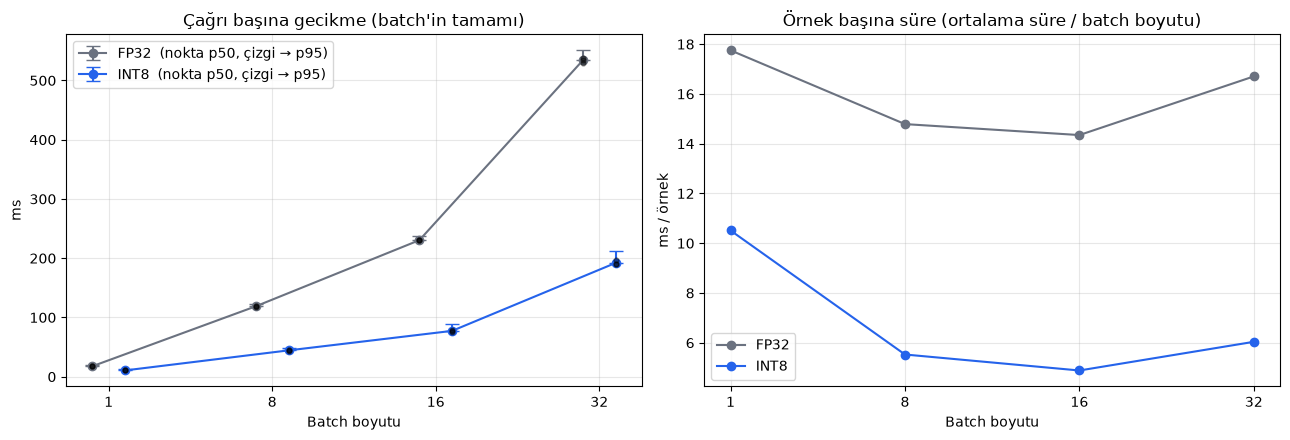

In [22]:
colors = {"FP32": "#6b7280", "INT8": "#2563eb"}
x_pos = np.arange(len(BATCH_SIZES))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for i, model_name in enumerate(["FP32", "INT8"]):
    sub = between[between.model == model_name].sort_values("batch_size")
    offset = -0.1 if model_name == "FP32" else 0.1
    p50 = sub["p50_ort"].values
    p95 = sub["p95_ort"].values
    axes[0].errorbar(x_pos + offset, p50, yerr=[np.zeros_like(p50), p95 - p50], fmt="o-", capsize=5,
                     color=colors[model_name], label=f"{model_name}  (nokta p50, çizgi → p95)")
    for j, bs in enumerate(BATCH_SIZES):
        run_vals = runs_df[(runs_df.model == model_name) & (runs_df.batch_size == bs)]["p50_ms"]
        axes[0].scatter([x_pos[j] + offset] * len(run_vals), run_vals, s=12, color="black", alpha=0.4, zorder=3)
    per_sample = runs_df[runs_df.model == model_name].groupby("batch_size")["ms_per_sample"].mean()
    axes[1].plot(x_pos, per_sample.values, "o-", color=colors[model_name], label=model_name)

axes[0].set_title("Çağrı başına gecikme (batch'in tamamı)")
axes[0].set_ylabel("ms")
axes[1].set_title("Örnek başına süre (ortalama süre / batch boyutu)")
axes[1].set_ylabel("ms / örnek")
for ax in axes:
    ax.set_xticks(x_pos, [str(b) for b in BATCH_SIZES])
    ax.set_xlabel("Batch boyutu")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/latency_comparison.png", dpi=150)
plt.show()

## 18. Throughput karşılaştırma grafiği

Çubuk yüksekliği 3 run'ın ortalama throughput'udur; hata çubuğu run'lar arası standart sapmadır.

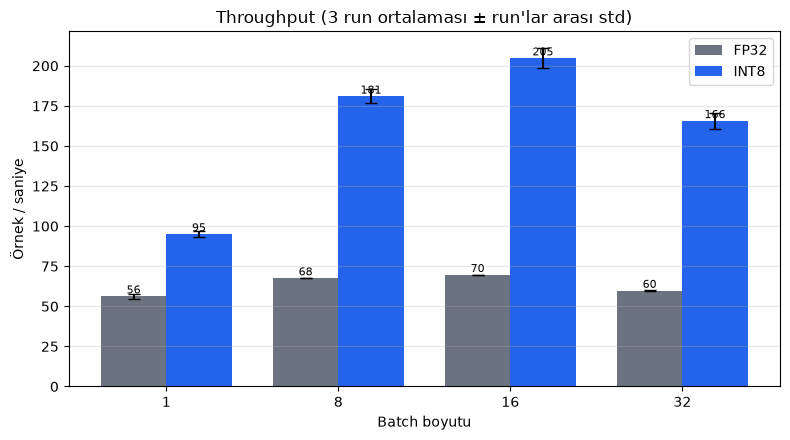

In [23]:
fig, ax = plt.subplots(figsize=(8, 4.5))
width = 0.38
for model_name, offset in [("FP32", -width / 2), ("INT8", width / 2)]:
    sub = between[between.model == model_name].sort_values("batch_size")
    ax.bar(x_pos + offset, sub["thr_ort"], width, yerr=sub["thr_runlar_std"], capsize=4,
           color=colors[model_name], label=model_name)
    for xi, val in zip(x_pos + offset, sub["thr_ort"]):
        ax.text(xi, val, f"{val:.0f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x_pos, [str(b) for b in BATCH_SIZES])
ax.set_xlabel("Batch boyutu")
ax.set_ylabel("Örnek / saniye")
ax.set_title("Throughput (3 run ortalaması ± run'lar arası std)")
ax.grid(alpha=0.3, axis="y")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/throughput_comparison.png", dpi=150)
plt.show()

## 19. Accuracy – latency trade-off grafiği

**Trade-off (ödünleşim):** Bir şeyi iyileştirirken başka bir şeyden vazgeçmek. Burada hız kazanırken doğruluktan ne kadar kaybettiğimize bakıyoruz.

- **Sol grafik (tek istek senaryosu, batch=1):** x ekseni gecikme (nokta p50, yatay çizgi p95'e kadar), y ekseni doğruluk (dikey çizgi %95 Wilson güven aralığı).
- **Sağ grafik (tüm 8 konfigürasyon):** x ekseni örnek başına süre (maliyetin göstergesi), y ekseni doğruluk.

**Sol üst köşe** en iyisidir: hızlı ve doğru. Dikey güven aralıkları üst üste biniyorsa iki modelin doğruluğu istatistiksel olarak ayırt edilemez.

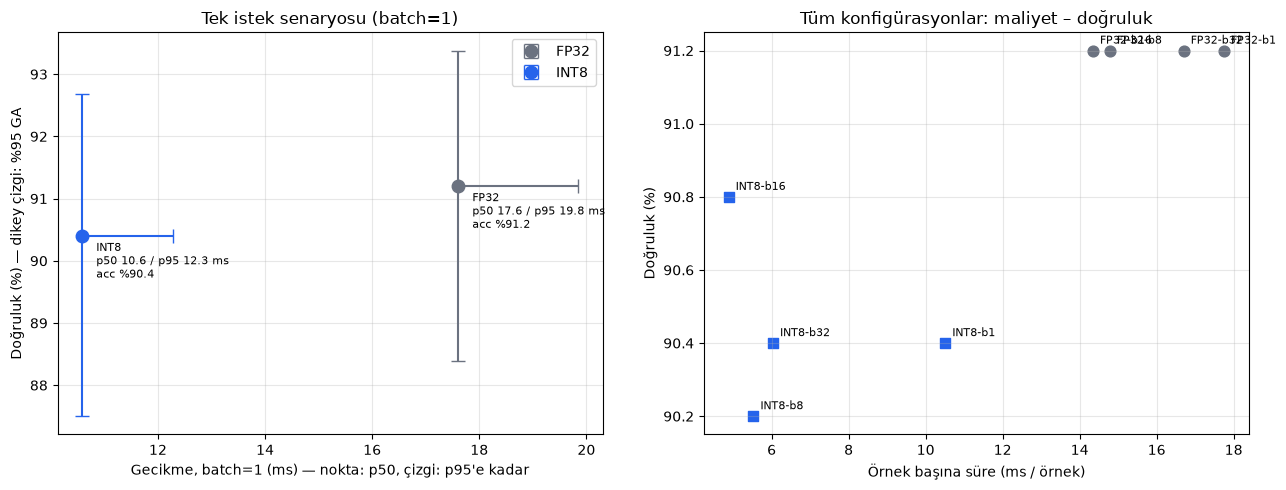

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for model_name in ["FP32", "INT8"]:
    r = between[(between.model == model_name) & (between.batch_size == 1)].iloc[0]
    preds, acc = ACC[(model_name, 1)]
    lo, hi = wilson_ci(int((preds == labels).sum()), len(labels))
    axes[0].errorbar(r["p50_ort"], 100 * acc, xerr=[[0], [r["p95_ort"] - r["p50_ort"]]],
                     yerr=[[100 * (acc - lo)], [100 * (hi - acc)]], fmt="o", ms=9, capsize=5,
                     color=colors[model_name], label=model_name)
    axes[0].annotate(f"{model_name}\np50 {r['p50_ort']:.1f} / p95 {r['p95_ort']:.1f} ms\nacc %{100*acc:.1f}",
                     (r["p50_ort"], 100 * acc), textcoords="offset points", xytext=(10, -30), fontsize=8)
axes[0].set_xlabel("Gecikme, batch=1 (ms) — nokta: p50, çizgi: p95'e kadar")
axes[0].set_ylabel("Doğruluk (%) — dikey çizgi: %95 GA")
axes[0].set_title("Tek istek senaryosu (batch=1)")

for model_name, marker in [("FP32", "o"), ("INT8", "s")]:
    for bs in BATCH_SIZES:
        per_sample = runs_df[(runs_df.model == model_name) & (runs_df.batch_size == bs)]["ms_per_sample"].mean()
        acc = 100 * ACC[(model_name, bs)][1]
        axes[1].scatter(per_sample, acc, marker=marker, s=60, color=colors[model_name])
        axes[1].annotate(f"{model_name}-b{bs}", (per_sample, acc), textcoords="offset points", xytext=(5, 5), fontsize=8)
axes[1].set_xlabel("Örnek başına süre (ms / örnek)")
axes[1].set_ylabel("Doğruluk (%)")
axes[1].set_title("Tüm konfigürasyonlar: maliyet – doğruluk")

for ax in axes:
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.savefig(f"{OUT}/accuracy_latency_tradeoff.png", dpi=150)
plt.show()

## 19b. Önceki çalışmanın sonuçlarıyla karşılaştırma (referans)

**Uyarılar (raporda da belirtin):**
1. Önceki sonuçların kodu elimizde değildir; ölçüm koşulları (donanım, tekrar sayısı, girdi seçimi, kütüphane sürümleri) bilinmemektedir.
2. Throughput × ortalama gecikme hesabı önceki "tekil" ölçümlerin **batch boyutu 16 ile yapılmış olabileceğini** gösterir. Bu **doğrulanmamış bir çıkarımdır.** Bu yüzden yeni sonuçların yalnızca batch=16 satırı yan yana konur.
3. Önceki batch=8 özetinin hangi tabana göre hesaplandığı kayıtlı değildir. Yeni hesapta taban olarak **aynı batch boyutundaki FP32** alınmıştır.

In [25]:
print("Önceki tekil ölçümlerde bir çağrıdaki tahmini örnek sayısı (throughput × ortalama süre):")
for name, old in OLD_RESULTS.items():
    implied = old["throughput_sps"] * old["mean_ms"] / 1000
    print(f"  {name}: {old['throughput_sps']} × {old['mean_ms']/1000:.6f} s = {implied:.2f} örnek  →  DOĞRULANMAMIŞ ÇIKARIM: batch≈{round(implied)}")

compare_rows = []
for name, old in OLD_RESULTS.items():
    compare_rows.append({"Kaynak": name + " [kodu yok, referans]", "Accuracy %": old["accuracy_pct"],
                         "P50 ms": old["p50_ms"], "P95 ms": old["p95_ms"], "Std ms": old["std_ms"],
                         "Throughput": old["throughput_sps"], "Dosya MB": old["model_size_mb"]})
for model_name in ["FP32", "INT8"]:
    r = between[(between.model == model_name) & (between.batch_size == 16)].iloc[0]
    compare_rows.append({"Kaynak": f"{model_name} (yeni, batch=16)", "Accuracy %": round(100 * ACC[(model_name, 16)][1], 2),
                         "P50 ms": round(r["p50_ort"], 3), "P95 ms": round(r["p95_ort"], 3),
                         "Std ms": round(r["run_ici_std_ort"], 3), "Throughput": round(r["thr_ort"], 3),
                         "Dosya MB": round(size_fp32_mb if model_name == "FP32" else size_int8_mb, 2)})
compare_df = pd.DataFrame(compare_rows)
compare_df.to_csv(f"{OUT}/comparison_with_previous.csv", index=False, encoding="utf-8-sig")
print()
print(compare_df.to_string(index=False))

def get_cell(model_name, bs):
    return between[(between.model == model_name) & (between.batch_size == bs)].iloc[0]
f8, q8 = get_cell("FP32", 8), get_cell("INT8", 8)
new_b8 = {
    "p95_azalma_pct": 100 * (1 - q8["p95_ort"] / f8["p95_ort"]),
    "throughput_artis_pct": 100 * (q8["thr_ort"] / f8["thr_ort"] - 1),
    "accuracy_fark_puan": 100 * (ACC[("INT8", 8)][1] - ACC[("FP32", 8)][1]),
    "model_boyutu_azalma_pct": reduction_pct,
}
print("\nBatch=8 özeti (yeni: INT8-b8, FP32-b8'e göre):")
for key in OLD_BATCH8_SUMMARY:
    print(f"  {key:26s}: önceki {OLD_BATCH8_SUMMARY[key]:8.2f}  |  yeni {new_b8[key]:8.2f}")

Önceki tekil ölçümlerde bir çağrıdaki tahmini örnek sayısı (throughput × ortalama süre):
  FP32 (önceki): 66.897 × 0.239172 s = 16.00 örnek  →  DOĞRULANMAMIŞ ÇIKARIM: batch≈16
  INT8 (önceki): 200.954 × 0.079620 s = 16.00 örnek  →  DOĞRULANMAMIŞ ÇIKARIM: batch≈16

                            Kaynak  Accuracy %  P50 ms  P95 ms  Std ms  Throughput  Dosya MB
FP32 (önceki) [kodu yok, referans]        91.2 238.547 252.402  10.587      66.897    255.43
INT8 (önceki) [kodu yok, referans]        90.8  79.139  83.824   2.632     200.954    132.29
             FP32 (yeni, batch=16)        91.2 230.447 237.535   6.484      69.701    267.86
             INT8 (yeni, batch=16)        90.8  77.325  89.767   4.812     204.837    138.72

Batch=8 özeti (yeni: INT8-b8, FP32-b8'e göre):
  p95_azalma_pct            : önceki    60.64  |  yeni    61.14
  throughput_artis_pct      : önceki   158.98  |  yeni   167.65
  accuracy_fark_puan        : önceki    -1.00  |  yeni    -1.00
  model_boyutu_azalma_pct   : 

**Çıktıyı nasıl okumalı?** Mutlak süreler farklı bilgisayarlarda doğal olarak farklı çıkar; doğrudan karşılaştırmayın. Karşılaştırılabilir olan **oranlardır**: hızlanma katı, boyut azalması, doğruluk farkının yönü. Oranlar benzerse önceki bulgu yeniden üretilmiş (*replicated*) demektir. Model boyutu azalması aynı model ve aynı yöntemle yapıldığı için önceki %48,21'e çok yakın çıkmalıdır.

## 20. Sonuç ve değerlendirme

Önce ortamın deney boyunca değişmediğini kontrol ediyoruz. Ardından notebook, **bu çalıştırmanın gerçek sayılarıyla** bir yorum taslağı üretir (`results/yorum_taslak.md`). Bu bir **taslaktır**: teslim etmeden önce kendi cümlelerinizle düzenleyin.

In [26]:
ENV_END = environment_fingerprint()
changed = {}
for key in ENV_START:
    if ENV_START[key] != ENV_END[key]:
        changed[key] = (ENV_START[key], ENV_END[key])
if changed:
    print("UYARI: ortam değişti! Notebook'u baştan çalıştırın ve raporda belirtin:", changed)
else:
    print(f"Tüm ölçümler aynı ortamda yapıldı: {ENV_END['islemci']} | {ENV_END['isletim_sistemi']} | {N_THREADS} iş parçacığı")

primary = stats_df[stats_df.batch_size == 1].iloc[0]
f1, q1 = get_cell("FP32", 1), get_cell("INT8", 1)
f32, q32 = get_cell("FP32", 32), get_cell("INT8", 32)
speedup_b1 = f1["p50_ort"] / q1["p50_ort"]
significance = "istatistiksel olarak anlamlı değil" if primary["McNemar p"] >= 0.05 else "istatistiksel olarak anlamlı"

summary_text = f'''**Beklenti.** Dynamic quantization'ın CPU'da gecikmeyi yaklaşık 2–3 kat azaltmasını, model boyutunu %75 küçültmesini ve doğruluğu 1 puandan az düşürmesini; batching'in ise örnek başına maliyeti düşürüp throughput'u artırmasını bekledik.

**Sonuç.** Batch=1'de quantization gecikmeyi p50 {f1['p50_ort']:.1f} → {q1['p50_ort']:.1f} ms, p95 {f1['p95_ort']:.1f} → {q1['p95_ort']:.1f} ms düşürdü ({speedup_b1:.2f} kat; 3 run). Doğruluk %{primary['FP32 acc %']:.1f} → %{primary['INT8 acc %']:.1f} ({primary['Fark (puan)']:+.1f} puan; McNemar p = {primary['McNemar p']:.3f}, {significance}; farkın %95 GA [{primary['Bootstrap GA alt']:.1f}, {primary['Bootstrap GA üst']:.1f}] puan). Pratik değerlendirme: {primary['Pratik karar'].lower()}. Model dosyası {size_fp32_mb:.0f} → {size_int8_mb:.0f} MB küçüldü (%{reduction_pct:.1f}), beklenen %75'in altında. Batch=32, throughput'u FP32'de {f1['thr_ort']:.0f} → {f32['thr_ort']:.0f}, INT8'de {q1['thr_ort']:.0f} → {q32['thr_ort']:.0f} örnek/s'ye çıkardı; ancak çağrı başına gecikme arttı.

**Olası nedenler.** INT8 matris çarpımı daha az hesap ve 4 kat daha az bellek trafiği gerektirir. Boyutun %75 küçülmemesinin nedeni, parametrelerin yaklaşık üçte birini oluşturan embedding tablosunun quantize edilmemesidir. Dynamic quantization aktivasyon ölçeğini batch'e göre hesapladığından INT8 doğruluğu batch boyutuyla biraz değişebilir. Batching kazancı dolgu (padding) ve çekirdek sayısıyla sınırlıdır.

**Sonraki adım.** Cümleleri uzunluğa göre gruplayarak dolguyu azaltmak, ONNX Runtime ve statik quantization'ı denemek, 872 örneğin tamamıyla doğruluk belirsizliğini azaltmak ve eş zamanlı istek yükü altında p95'i ölçmek.
'''
with open(f"{OUT}/yorum_taslak.md", "w", encoding="utf-8") as f:
    f.write(summary_text)
print()
print(summary_text)
print("Kaydedilen dosyalar:", sorted(os.listdir(OUT)))

Tüm ölçümler aynı ortamda yapıldı: AMD64 Family 26 Model 96 Stepping 0, AuthenticAMD | Windows 10 | 8 iş parçacığı

**Beklenti.** Dynamic quantization'ın CPU'da gecikmeyi yaklaşık 2–3 kat azaltmasını, model boyutunu %75 küçültmesini ve doğruluğu 1 puandan az düşürmesini; batching'in ise örnek başına maliyeti düşürüp throughput'u artırmasını bekledik.

**Sonuç.** Batch=1'de quantization gecikmeyi p50 17.6 → 10.6 ms, p95 19.8 → 12.3 ms düşürdü (1.66 kat; 3 run). Doğruluk %91.2 → %90.4 (-0.8 puan; McNemar p = 0.454, istatistiksel olarak anlamlı değil; farkın %95 GA [-2.4, 0.8] puan). Pratik değerlendirme: belirsiz: aralık −1.0 puanı içeriyor; 500 örnek karar için yetersiz. Model dosyası 268 → 139 MB küçüldü (%48.2), beklenen %75'in altında. Batch=32, throughput'u FP32'de 56 → 60, INT8'de 95 → 166 örnek/s'ye çıkardı; ancak çağrı başına gecikme arttı.

**Olası nedenler.** INT8 matris çarpımı daha az hesap ve 4 kat daha az bellek trafiği gerektirir. Boyutun %75 küçülmemesinin nedeni, paramet

### Hangi senaryoda hangi konfigürasyon?

Kararı yalnızca hıza bakarak vermeyin; senaryo belirler. Aşağıdaki tabloyu kendi sayılarınızla kontrol edin:

| Senaryo | Öncelik | Olası seçim | Kontrol edilecek |
|---|---|---|---|
| Gerçek zamanlı API, sohbet botu | Düşük p95 | INT8, batch=1 (veya çok küçük batch) | Bölüm 15b'nin pratik kararı "önemsiz" mi? |
| Gece çalışan toplu etiketleme | Throughput, maliyet | INT8, en yüksek throughput veren batch | Bölüm 18'de doyma noktası |
| Doğruluktan ödün verilemeyen alan | Birebir aynı çıktı | FP32 | Tahmin uyumu %100 değilse INT8 riskli |
| Kısıtlı RAM / disk | Bellek | INT8 | Bölüm 13 dosya boyutu, Bölüm 14 tensör belleği ve RSS artışı |

### Sınırlılıklar
- Tek bir bilgisayarda ölçüldü; sonuçlar başka işlemcilere doğrudan genellenemez (INT8 hızlanması işlemcinin komut desteğine bağlıdır).
- Doğruluk 500 örnekle ölçüldü; güven aralıkları ±2–3 puan civarındadır.
- Run'lar aynı Python sürecinde yapıldı; tamamen bağımsız değildir.
- Benchmark sabit 32 cümlelik bir havuzla yapıldı; gerçek trafikte cümle uzunluğu dağılımı farklı olabilir.
- Eş zamanlı istekler (concurrency) ve batch'in dolmasını bekleme süresi ölçülmedi.

In [27]:
import os
print(os.getcwd())

C:\Users\Merve Kartal\Desktop
